# 05 · Satisfação do cliente

**Pergunta:** o cliente está satisfeito? O que mais pesa na nota: entrega, preço, frete, produto ou vendedor?

Base: pedidos de jan/2017 a ago/2018 com avaliação (nota de 1 a 5). **Nota baixa** = 1 ou 2. Para um indicador no estilo NPS, tratamos nota 5 como promotor, 4 como neutro e 1 a 3 como detrator.

## Principais conclusões

- **Satisfação boa na média, com uma cauda relevante:** nota média de 4,09, com 77% de notas 4–5 e 14,6% de notas 1–2 (indicador estilo NPS de 35).
- **Entrega é o problema número 1:** pedidos atrasados ou não entregues são 9,3% do total, mas 43% das notas baixas. Mês a mês, atraso e notas baixas andam juntos (correlação de 0,89).
- **O modelo confirma o peso de cada fator** (AUC de 0,75): o atraso multiplica por 6,7 a chance de nota baixa; pedidos com mais de um vendedor, por 3,9; com mais de um item, por 3,0; cada semana a mais de prazo, por 1,45. O peso do frete não tem efeito relevante.
- **Na voz do cliente**, 75% das notas 1–2 vêm com comentário: 44% falam de não ter recebido ou de atraso, e 16% de produto errado ou incompleto.
- **Pontos de atenção:** Móveis de escritório tem 22% de notas baixas; 24 vendedores críticos têm 17% de atraso, contra 7% na média.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from olist import config, data, prep, viz
from olist.viz import CORES, brl, num, pct

viz.aplicar_estilo()
import re
import unicodedata
from collections import Counter

import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

In [2]:
pedidos = prep.carregar_base_pedidos()
avaliados = pedidos.dropna(subset=["review_score"]).copy()
avaliados["situacao"] = np.select(
    [~avaliados.entregue, avaliados.atrasado == 1], ["Não entregue", "Entregue com atraso"], default="Entregue no prazo")

## 1. Distribuição das notas

Nota média: 4.09 | notas 4–5: 77,1% | notas 1–2: 14,6%
Promotores (5): 57,8% | detratores (1–3): 22,9% | indicador estilo NPS: 35


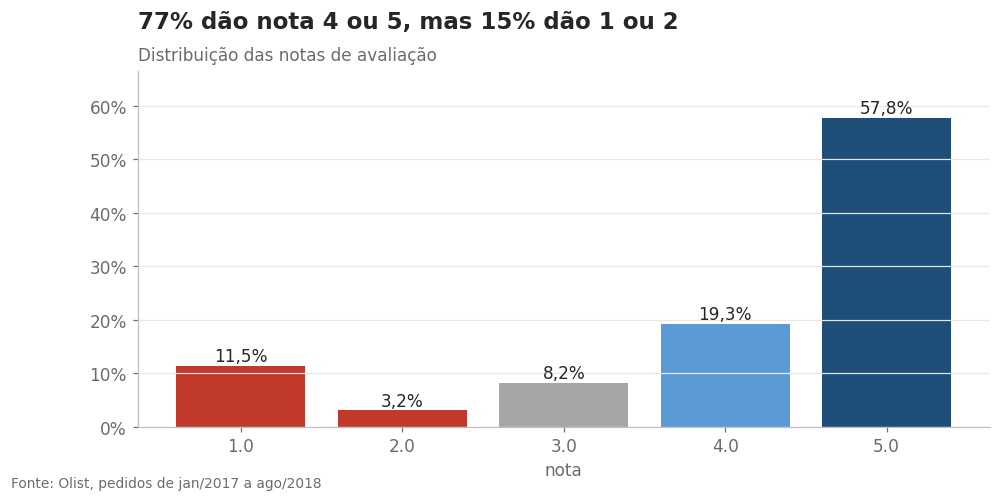

In [3]:
dist = avaliados.review_score.value_counts(normalize=True).sort_index()
promotores, detratores = dist[5], dist[[1, 2, 3]].sum()
nps = promotores - detratores
print(f"Nota média: {avaliados.review_score.mean():.2f} | notas 4–5: {pct(dist[[4, 5]].sum())} | notas 1–2: {pct(dist[[1, 2]].sum())}")
print(f"Promotores (5): {pct(promotores)} | detratores (1–3): {pct(detratores)} | indicador estilo NPS: {nps * 100:.0f}")

fig, ax = plt.subplots(figsize=(10, 4.2))
cores = [CORES["negativo"], CORES["negativo"], CORES["neutro"], CORES["secundaria"], CORES["principal"]]
barras = ax.bar(dist.index.astype(str), dist.values, color=cores)
for barra, v in zip(barras, dist.values):
    ax.text(barra.get_x() + barra.get_width() / 2, v, pct(v), ha="center", va="bottom")
ax.yaxis.set_major_formatter(viz.eixo_pct)
ax.set_xlabel("nota")
ax.set_ylim(0, dist.max() * 1.15)
viz.titulo(ax, f"{pct(dist[[4, 5]].sum(), 0)} dão nota 4 ou 5, mas {pct(dist[[1, 2]].sum(), 0)} dão 1 ou 2",
           "Distribuição das notas de avaliação")
viz.fonte(fig)
viz.salvar(fig, "05_distribuicao_notas")

## 2. De onde vêm as notas baixas

In [4]:
sit = avaliados.groupby("situacao").agg(avaliacoes=("order_id", "size"), nota=("review_score", "mean"), nota_baixa=("nota_baixa", "mean"),
                                        baixas=("nota_baixa", "sum"))
sit["% das avaliações"] = sit.avaliacoes / sit.avaliacoes.sum()
sit["% das notas baixas"] = sit.baixas / sit.baixas.sum()
sit = sit.reindex(["Entregue no prazo", "Entregue com atraso", "Não entregue"])
problema_entrega = sit.loc[["Entregue com atraso", "Não entregue"], "% das notas baixas"].sum()
peso_entrega = sit.loc[["Entregue com atraso", "Não entregue"], "% das avaliações"].sum()
print(f"Atraso ou não entrega: {pct(peso_entrega)} das avaliações e {pct(problema_entrega)} das notas baixas")
sit.drop(columns="baixas").assign(
    nota=sit.nota.round(2), nota_baixa=sit.nota_baixa.map(pct),
    **{"% das avaliações": sit["% das avaliações"].map(pct), "% das notas baixas": sit["% das notas baixas"].map(pct)})

Atraso ou não entrega: 9,3% das avaliações e 42,7% das notas baixas


,avaliacoes,nota,nota_baixa,% das avaliações,% das notas baixas
situacao,,,,,
Entregue no prazo,89182,4.29,"9,2%","90,7%","57,3%"
Entregue com atraso,6378,2.27,"62,4%","6,5%","27,7%"
Não entregue,2770,1.75,"77,8%","2,8%","15,0%"


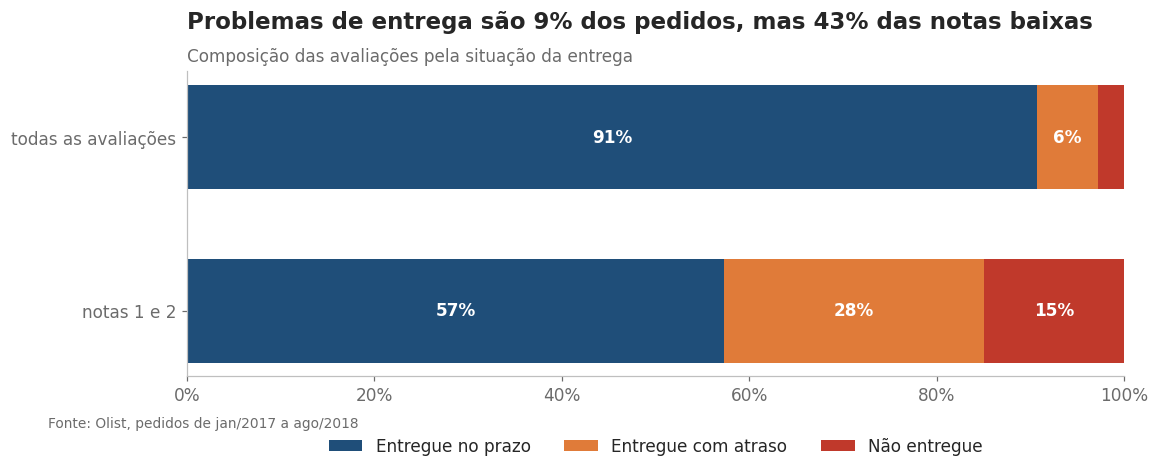

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.6))
cores = {"Entregue no prazo": CORES["principal"], "Entregue com atraso": CORES["destaque"], "Não entregue": CORES["negativo"]}
for y, coluna in enumerate(["% das avaliações", "% das notas baixas"]):
    inicio = 0
    for situacao, v in sit[coluna].items():
        ax.barh(y, v, left=inicio, color=cores[situacao], height=0.6, label=situacao if y == 0 else None)
        if v > 0.04:
            ax.text(inicio + v / 2, y, pct(v, 0), ha="center", va="center", color="white", fontweight="bold")
        inicio += v
ax.set_yticks([0, 1], ["todas as avaliações", "notas 1 e 2"])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(viz.eixo_pct)
ax.set_xlim(0, 1)
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
viz.titulo(ax, f"Problemas de entrega são {pct(peso_entrega, 0)} dos pedidos, mas {pct(problema_entrega, 0)} das notas baixas",
           "Composição das avaliações pela situação da entrega")
viz.fonte(fig)
viz.salvar(fig, "05_origem_notas_baixas")

## 3. Satisfação ao longo do tempo

Correlação mensal entre % de atraso e % de notas baixas: 0.89


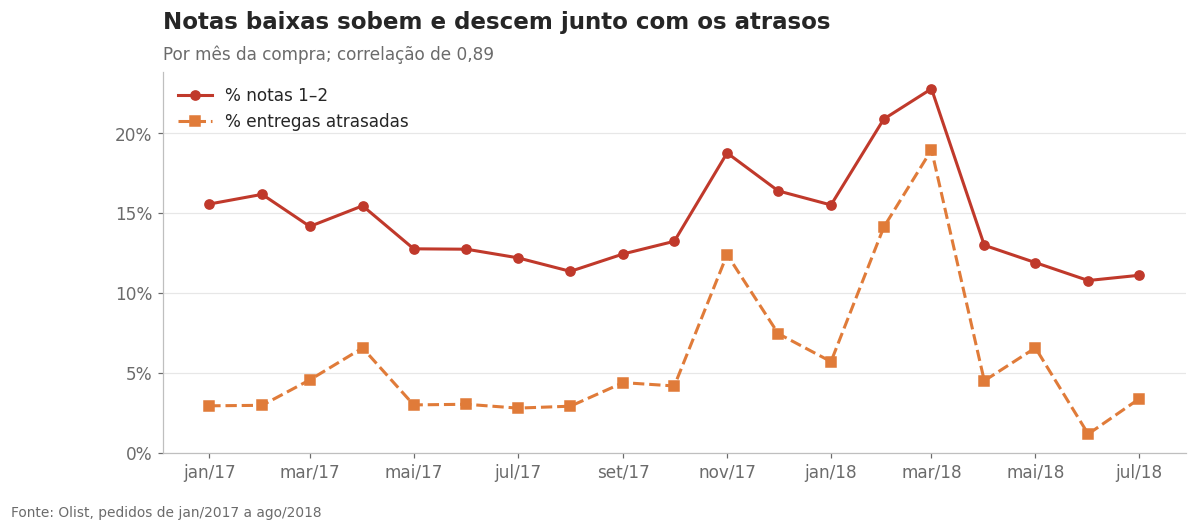

In [6]:
periodo = pedidos[prep.no_periodo(pedidos.order_purchase_timestamp, config.INICIO_JANELA, config.FIM_MES_COMPLETO)]
mensal = periodo.groupby("mes").agg(nota_baixa=("nota_baixa", "mean"), atraso=("atrasado", "mean"), nota=("review_score", "mean"))
correlacao = mensal.nota_baixa.corr(mensal.atraso)
print(f"Correlação mensal entre % de atraso e % de notas baixas: {correlacao:.2f}")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(mensal.index, mensal.nota_baixa, color=CORES["negativo"], marker="o", lw=2, label="% notas 1–2")
ax.plot(mensal.index, mensal.atraso, color=CORES["destaque"], marker="s", lw=2, ls="--", label="% entregas atrasadas")
ax.yaxis.set_major_formatter(viz.eixo_pct)
ax.xaxis.set_major_formatter(viz.eixo_mes)
ax.set_ylim(0, None)
ax.legend(loc="upper left")
viz.titulo(ax, "Notas baixas sobem e descem junto com os atrasos", f"Por mês da compra; correlação de {correlacao:.2f}".replace(".", ","))
viz.fonte(fig)
viz.salvar(fig, "05_notas_vs_atraso_mensal")

## 4. Fatores da nota baixa (pedidos entregues)

Primeiro uma comparação simples entre grupos; depois um modelo que mede o efeito de cada fator **mantendo os demais constantes**.

In [7]:
ent = avaliados[avaliados.entregue].copy()
no_prazo = ent.atrasado == 0
fatores = {
    "Pontualidade": pd.Series(np.where(no_prazo, "No prazo", "Atrasado"), index=ent.index),
    "Velocidade (só no prazo)": pd.cut(ent.dias_entrega.where(no_prazo), [0, 7, 14, 21, np.inf], labels=["até 7 dias", "8–14 dias", "15–21 dias", "22+ dias"]),
    "Vendedores no pedido": pd.Series(np.where(ent.n_sellers > 1, "2 ou mais", "1"), index=ent.index),
    "Itens no pedido": pd.Series(np.where(ent.n_itens > 1, "2 ou mais", "1"), index=ent.index),
    "Frete / valor do pedido": pd.cut(ent.perc_frete, [0, 0.1, 0.2, 0.3, 1], labels=["até 10%", "10–20%", "20–30%", "30%+"]),
    "Valor do pedido": pd.cut(ent.gmv, [0, 50, 100, 200, 500, np.inf], labels=["até R$ 50", "R$ 50–100", "R$ 100–200", "R$ 200–500", "R$ 500+"]),
}
linhas = []
for fator, grupos in fatores.items():
    g = ent.groupby(grupos, observed=True).agg(nota_baixa=("nota_baixa", "mean"), pedidos=("order_id", "size"))
    linhas += [(fator, grupo, linha.nota_baixa, linha.pedidos) for grupo, linha in g.iterrows()]
drivers = pd.DataFrame(linhas, columns=["fator", "grupo", "nota_baixa", "pedidos"])
drivers.assign(nota_baixa=drivers.nota_baixa.map(pct))

,fator,grupo,nota_baixa,pedidos
0,Pontualidade,Atrasado,"62,4%","6,378.00"
1,Pontualidade,No prazo,"9,2%","89,182.00"
2,Velocidade (só no prazo),até 7 dias,"7,4%","25,867.00"
3,Velocidade (só no prazo),8–14 dias,"8,8%","39,583.00"
4,Velocidade (só no prazo),15–21 dias,"10,7%","16,997.00"
5,Velocidade (só no prazo),22+ dias,"15,4%","6,735.00"
6,Vendedores no pedido,1,"12,3%","94,302.00"
7,Vendedores no pedido,2 ou mais,"47,1%","1,258.00"
8,Itens no pedido,1,"11,3%","86,061.00"
9,Itens no pedido,2 ou mais,"26,7%","9,499.00"


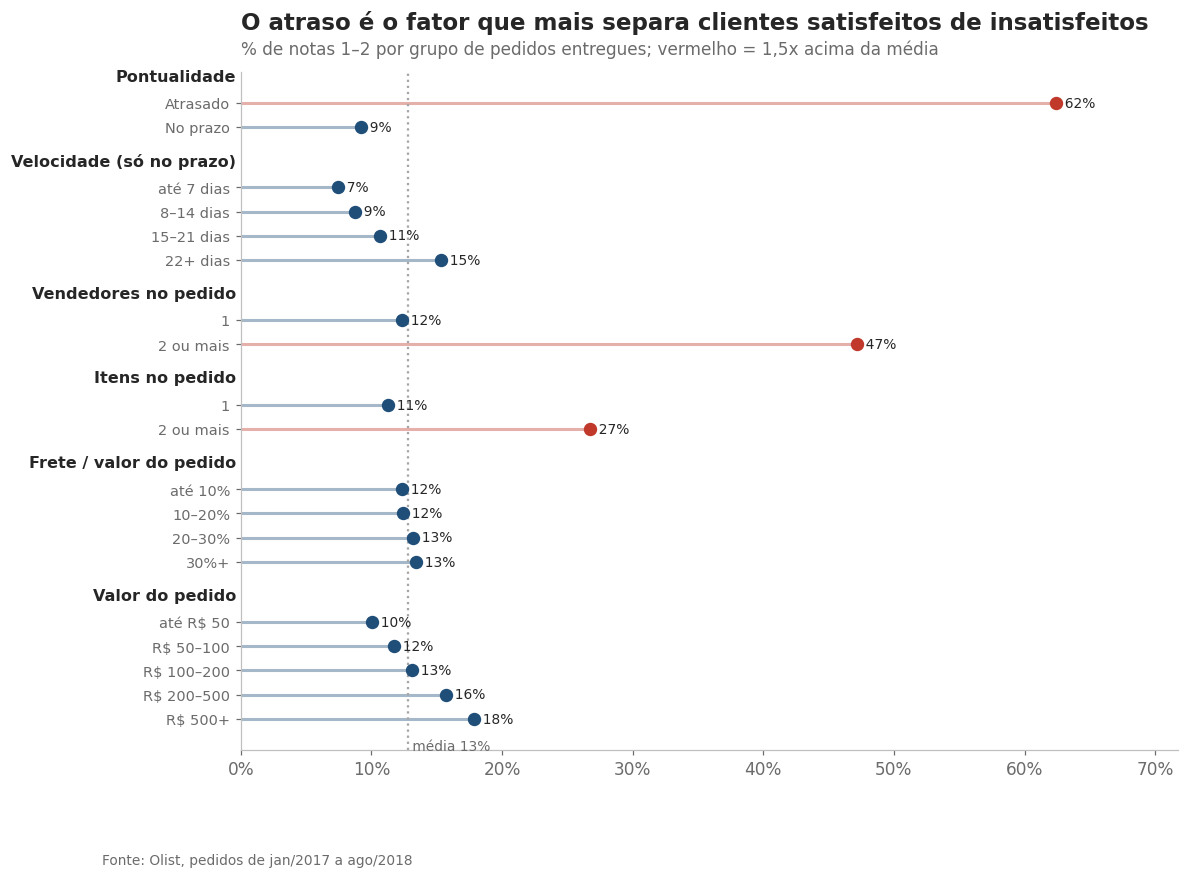

In [8]:
fig, ax = plt.subplots(figsize=(11, 8))
y, rotulos, posicoes = 0, [], []
media = ent.nota_baixa.mean()
for fator, g in drivers.groupby("fator", sort=False):
    ax.text(-0.005, y - 0.2, fator, fontweight="bold", ha="right", va="center", fontsize=10.5, transform=ax.get_yaxis_transform())
    y += 0.9
    for _, linha in g.iterrows():
        cor = CORES["negativo"] if linha.nota_baixa > media * 1.5 else CORES["principal"]
        ax.plot([0, linha.nota_baixa], [y, y], color=cor, lw=2, alpha=0.4)
        ax.scatter(linha.nota_baixa, y, color=cor, s=60, zorder=3)
        ax.text(linha.nota_baixa, y, f"  {pct(linha.nota_baixa, 0)}", va="center", fontsize=9)
        rotulos.append(linha.grupo)
        posicoes.append(y)
        y += 1
    y += 0.6
ax.axvline(media, color=CORES["neutro"], ls=":")
ax.text(media, posicoes[-1] + 1.3, f" média {pct(media, 0)}", color=CORES["subtexto"], fontsize=9)
ax.set_yticks(posicoes, rotulos, fontsize=9.5)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(viz.eixo_pct)
ax.set_xlim(0, drivers.nota_baixa.max() * 1.15)
ax.grid(axis="y", visible=False)
viz.titulo(ax, "O atraso é o fator que mais separa clientes satisfeitos de insatisfeitos",
           "% de notas 1–2 por grupo de pedidos entregues; vermelho = 1,5x acima da média")
viz.fonte(fig)
viz.salvar(fig, "05_fatores_nota_baixa")

### Modelo: quanto cada fator multiplica a chance de nota baixa

Regressão logística com a nota baixa como resposta. O resultado é apresentado como **razão de chances** (*odds ratio*): 2,0 significa que o fator dobra a chance de nota baixa, mantendo os outros fatores iguais.

In [9]:
base_modelo = ent.assign(
    atraso=ent.atrasado,
    dias_entrega_limitado=ent.dias_entrega.clip(upper=60),
    multi_vendedor=(ent.n_sellers > 1).astype(int),
    multi_item=(ent.n_itens > 1).astype(int),
    frete_pp=ent.perc_frete * 100,
    log_valor=np.log(ent.gmv),
    outro_estado=(~ent.mesma_uf).astype(int),
).dropna(subset=["nota_baixa", "dias_entrega_limitado", "frete_pp", "log_valor", "regiao"])

modelo = smf.logit(
    "nota_baixa ~ atraso + dias_entrega_limitado + multi_vendedor + multi_item + frete_pp + log_valor + outro_estado"
    " + C(regiao, Treatment('Sudeste'))",
    data=base_modelo,
).fit(disp=False)
auc = roc_auc_score(base_modelo.nota_baixa, modelo.predict(base_modelo))
print(f"Pedidos no modelo: {num(len(base_modelo))} | AUC: {auc:.2f}")

# Efeito para variações com significado de negócio
incrementos = {
    "atraso": (1, "Entrega atrasada"),
    "multi_vendedor": (1, "Pedido com 2+ vendedores"),
    "multi_item": (1, "Pedido com 2+ itens"),
    "dias_entrega_limitado": (7, "+7 dias de prazo de entrega"),
    "frete_pp": (10, "+10 p.p. de frete no pedido"),
    "log_valor": (np.log(2), "Pedido com o dobro do valor"),
    "outro_estado": (1, "Vendedor de outro estado"),
}
for termo in modelo.params.index:
    if termo.startswith("C(regiao"):
        incrementos[termo] = (1, "Cliente no " + termo.split("T.")[1].rstrip("]") + " (vs. Sudeste)")
ic = modelo.conf_int()
efeitos = pd.DataFrame([
    {"fator": rotulo, "razao_chances": np.exp(modelo.params[t] * inc), "ic_inf": np.exp(ic.loc[t, 0] * inc),
     "ic_sup": np.exp(ic.loc[t, 1] * inc), "p_valor": modelo.pvalues[t]}
    for t, (inc, rotulo) in incrementos.items()
]).sort_values("razao_chances")
efeitos.round(3)

Pedidos no modelo: 95.560 | AUC: 0.75


,fator,razao_chances,ic_inf,ic_sup,p_valor
9,Cliente no Norte (vs. Sudeste),0.65,0.56,0.77,0.00
8,Cliente no Nordeste (vs. Sudeste),0.75,0.70,0.81,0.00
10,Cliente no Sul (vs. Sudeste),0.80,0.75,0.86,0.00
7,Cliente no Centro-Oeste (vs. Sudeste),0.87,0.80,0.96,0.00
6,Vendedor de outro estado,0.92,0.87,0.97,0.00
4,+10 p.p. de frete no pedido,1.02,0.99,1.05,0.14
5,Pedido com o dobro do valor,1.04,1.01,1.07,0.01
3,+7 dias de prazo de entrega,1.45,1.42,1.48,0.00
2,Pedido com 2+ itens,2.98,2.78,3.19,0.00
1,Pedido com 2+ vendedores,3.94,3.48,4.47,0.00


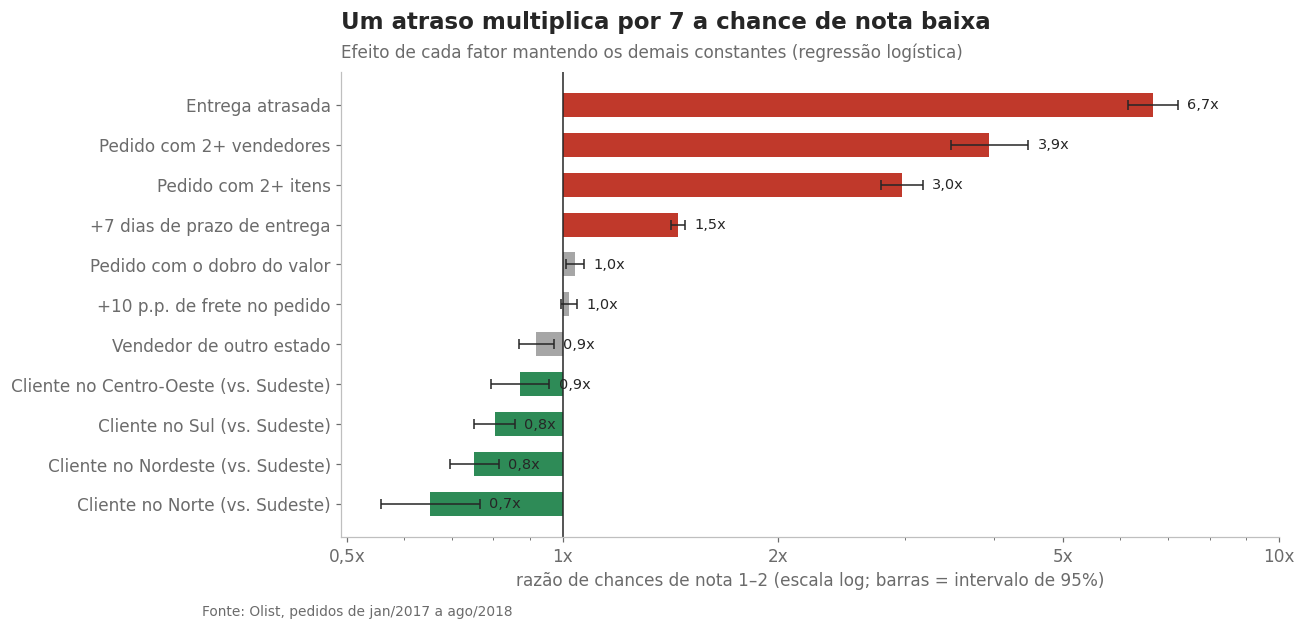

In [10]:
fig, ax = plt.subplots(figsize=(11, 5.5))
cores = [CORES["negativo"] if v > 1.1 else CORES["positivo"] if v < 0.9 else CORES["neutro"] for v in efeitos.razao_chances]
ax.barh(efeitos.fator, efeitos.razao_chances - 1, left=1, color=cores, height=0.6)
ax.errorbar(efeitos.razao_chances, efeitos.fator, xerr=[efeitos.razao_chances - efeitos.ic_inf, efeitos.ic_sup - efeitos.razao_chances],
            fmt="none", ecolor=CORES["texto"], capsize=3, lw=1)
for yi, v in enumerate(efeitos.razao_chances):
    ax.text(max(v, efeitos.ic_sup.iloc[yi]) * 1.03, yi, f"{v:.1f}x".replace(".", ","), va="center", fontsize=9.5)
ax.axvline(1, color=CORES["texto"], lw=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 1, 2, 5, 10], ["0,5x", "1x", "2x", "5x", "10x"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("razão de chances de nota 1–2 (escala log; barras = intervalo de 95%)")
fator_atraso = efeitos.set_index("fator").loc["Entrega atrasada", "razao_chances"]
viz.titulo(ax, f"Um atraso multiplica por {fator_atraso:.0f} a chance de nota baixa".replace(".", ","),
           "Efeito de cada fator mantendo os demais constantes (regressão logística)")
viz.fonte(fig)
viz.salvar(fig, "05_modelo_fatores")

## 5. Categorias com melhor e pior avaliação

Categorias com pelo menos 500 pedidos entregues. A coluna de atraso ajuda a separar problema de produto de problema de entrega.

In [11]:
cat = ent.groupby("categoria").agg(pedidos=("order_id", "size"), nota=("review_score", "mean"), nota_baixa=("nota_baixa", "mean"),
                                   atraso=("atrasado", "mean"))
cat = cat[cat.pedidos >= 500].sort_values("nota_baixa")
extremos = pd.concat([cat.head(6), cat.tail(6)])
extremos.assign(nota=extremos.nota.round(2), nota_baixa=extremos.nota_baixa.map(pct), atraso=extremos.atraso.map(pct))

,pedidos,nota,nota_baixa,atraso
categoria,,,,
Malas e acessórios,1008,4.37,"8,1%","4,2%"
Papelaria,2231,4.31,"9,7%","6,5%"
Bolsas e acessórios,1795,4.24,"10,0%","5,6%"
Pet shop,1670,4.28,"10,6%","5,0%"
Cool stuff,3495,4.23,"10,9%","5,8%"
Eletrodomésticos,744,4.21,"11,0%","4,4%"
Telefonia,4042,4.06,"13,9%","7,1%"
Informática e acessórios,6468,4.08,"14,5%","6,3%"
Móveis e decoração,6095,4.08,"14,8%","7,2%"


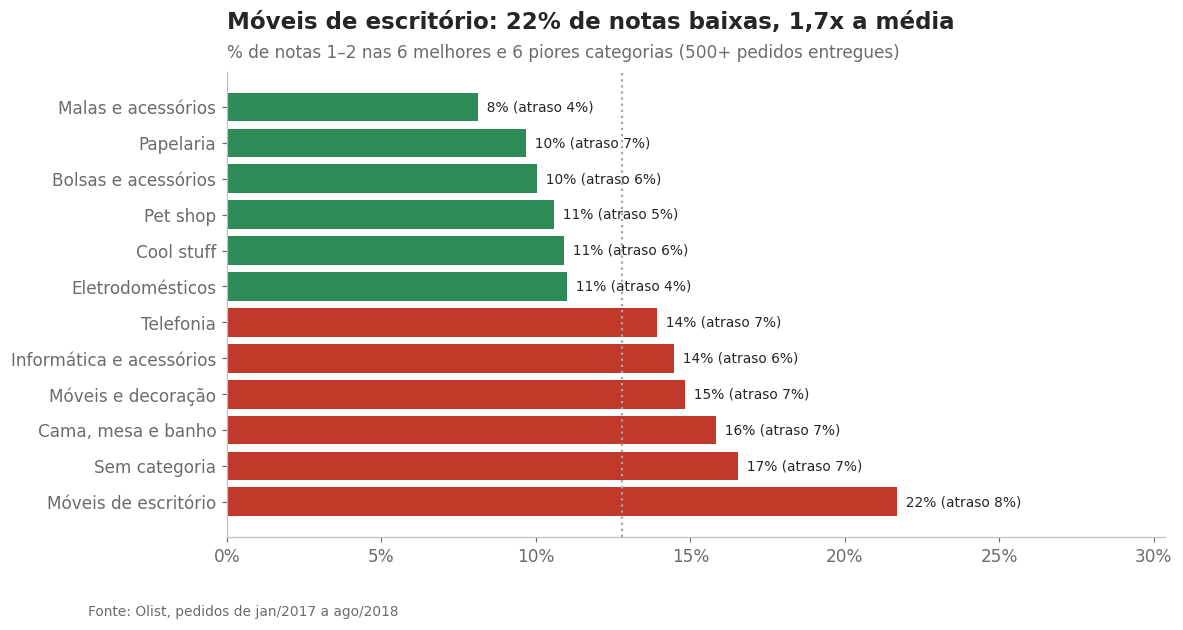

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.5))
cores = [CORES["positivo"]] * 6 + [CORES["negativo"]] * 6
ax.barh(extremos.index, extremos.nota_baixa, color=cores)
for yi, (v, a) in enumerate(zip(extremos.nota_baixa, extremos.atraso)):
    ax.text(v, yi, f"  {pct(v, 0)} (atraso {pct(a, 0)})", va="center", fontsize=9)
ax.axvline(ent.nota_baixa.mean(), color=CORES["neutro"], ls=":")
ax.invert_yaxis()
ax.xaxis.set_major_formatter(viz.eixo_pct)
ax.set_xlim(0, extremos.nota_baixa.max() * 1.4)
ax.grid(axis="y", visible=False)
pior = cat.index[-1]
viz.titulo(ax, f"{pior}: {pct(cat.nota_baixa.iloc[-1], 0)} de notas baixas, {cat.nota_baixa.iloc[-1] / ent.nota_baixa.mean():.1f}x a média".replace(".", ","),
           "% de notas 1–2 nas 6 melhores e 6 piores categorias (500+ pedidos entregues)")
viz.fonte(fig)
viz.salvar(fig, "05_categorias_nota")

## 6. O que os clientes escrevem

Mineração de texto dos comentários: termos mais frequentes (pares de palavras) nas notas baixas e altas, e classificação das reclamações por tema a partir de palavras-chave.

Comentam a avaliação: 41,2% do total | 74,7% das notas 1–2


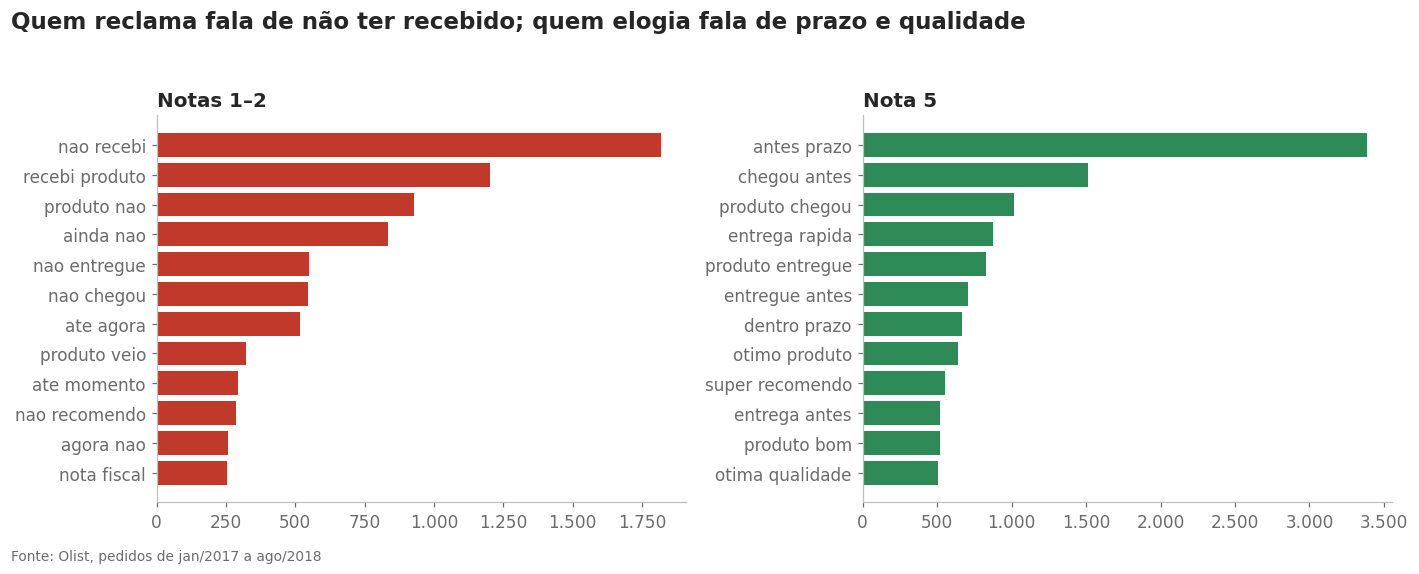

In [13]:
STOPWORDS = set('''
a o as os e de da do das dos em no na nos nas um uma uns umas para pra por com que se ao aos the
foi era ser sao esta estou este essa esse isso isto ja mas mais muito muita bem como eu me meu minha
voce ele ela tem ter tive havia porem pois quando qual ou nem sobre entre tambem lo la lhe nao_
'''.split())

def normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto).lower()).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z\s]", " ", texto)

def bigramas(textos):
    contagem = Counter()
    for texto in textos:
        palavras = [p for p in normalizar(texto).split() if p not in STOPWORDS and len(p) > 1]
        contagem.update(" ".join(par) for par in zip(palavras, palavras[1:]))
    return pd.Series(dict(contagem.most_common(12)))

comentados = avaliados.dropna(subset=["review_comment_message"])
baixas = comentados.loc[comentados.review_score <= 2, "review_comment_message"]
altas = comentados.loc[comentados.review_score == 5, "review_comment_message"]
print(f"Comentam a avaliação: {pct(avaliados.tem_comentario.mean())} do total | {pct(avaliados.loc[avaliados.review_score <= 2, 'tem_comentario'].mean())} das notas 1–2")

top_baixas, top_altas = bigramas(baixas), bigramas(altas)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, serie, cor, nome in [(axes[0], top_baixas, CORES["negativo"], "Notas 1–2"), (axes[1], top_altas, CORES["positivo"], "Nota 5")]:
    serie = serie.iloc[::-1]
    ax.barh(serie.index, serie.values, color=cor)
    ax.xaxis.set_major_formatter(viz.eixo_num)
    ax.grid(axis="y", visible=False)
    ax.set_title(nome, fontsize=13, pad=6)
fig.suptitle("Quem reclama fala de não ter recebido; quem elogia fala de prazo e qualidade", x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
viz.fonte(fig)
viz.salvar(fig, "05_termos_comentarios")

Defeito ou baixa qualidade       12,7%
Produto errado ou incompleto     16,2%
Atendimento, troca ou estorno    17,5%
Outros                           28,7%
Não recebeu ou atraso            43,8%


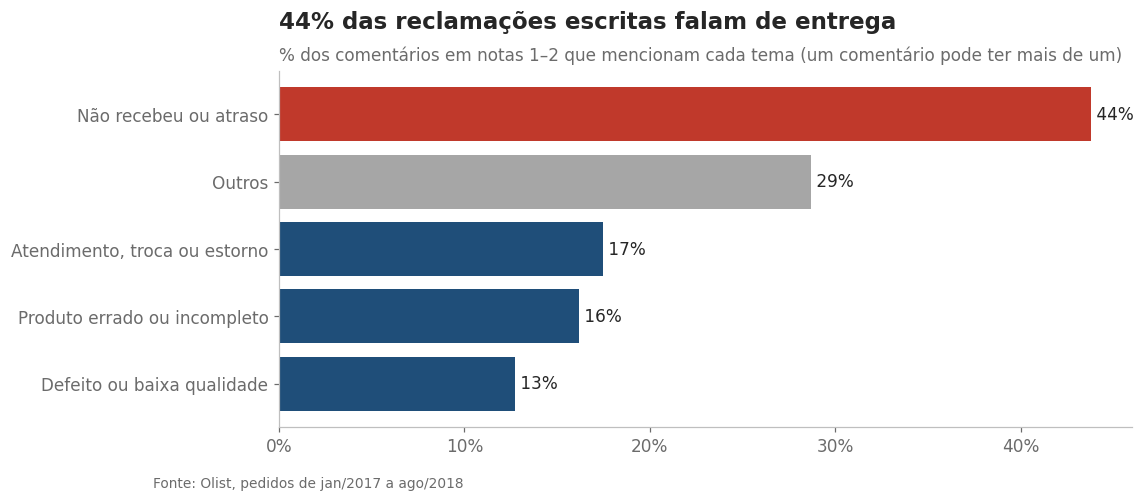

In [14]:
TEMAS = {
    "Não recebeu ou atraso": r"nao (?:recebi|chegou|foi entregue|entregaram|veio)|ainda nao|atras|prazo|demor|aguardando|esperando|nao entreg",
    "Produto errado ou incompleto": r"errad|diferente|falt|incomplet|apenas um|apenas uma|so veio|somente um|veio (?:so|apenas)|outro produto|trocad|faltou",
    "Defeito ou baixa qualidade": r"defeit|quebrad|qualidade|danific|nao funciona|estragad|rasgad|pessim|ruim|fragil",
    "Atendimento, troca ou estorno": r"atendimento|resposta|contato|devolu|reembols|estorno|cancel|troca|sac",
}
texto_baixas = baixas.map(normalizar)
temas = pd.DataFrame({tema: texto_baixas.str.contains(regex) for tema, regex in TEMAS.items()})
temas["Outros"] = ~temas.any(axis=1)
participacao = temas.mean().sort_values()
print(participacao.map(pct).to_string())

fig, ax = plt.subplots(figsize=(10, 4.2))
cores = [CORES["negativo"] if t == "Não recebeu ou atraso" else CORES["neutro"] if t == "Outros" else CORES["principal"] for t in participacao.index]
ax.barh(participacao.index, participacao.values, color=cores)
for yi, v in enumerate(participacao.values):
    ax.text(v, yi, f" {pct(v, 0)}", va="center")
ax.xaxis.set_major_formatter(viz.eixo_pct)
ax.grid(axis="y", visible=False)
viz.titulo(ax, f"{pct(participacao['Não recebeu ou atraso'], 0)} das reclamações escritas falam de entrega",
           "% dos comentários em notas 1–2 que mencionam cada tema (um comentário pode ter mais de um)")
viz.fonte(fig)
viz.salvar(fig, "05_temas_reclamacoes")

## 7. Concentração das notas baixas por vendedor

In [15]:
por_vendedor = avaliados.groupby("seller_id").agg(pedidos=("order_id", "size"), baixas=("nota_baixa", "sum"), atraso=("atrasado", "mean"))
por_vendedor["taxa"] = por_vendedor.baixas / por_vendedor.pedidos
media_geral = avaliados.nota_baixa.mean()
# Vendedor crítico: volume relevante e taxa de notas baixas de pelo menos o dobro da média
criticos = por_vendedor[(por_vendedor.pedidos >= 30) & (por_vendedor.taxa >= 2 * media_geral)]
print(f"Vendedores com 30+ pedidos avaliados: {num((por_vendedor.pedidos >= 30).sum())}")
print(f"Vendedores críticos (nota baixa >= {pct(2 * media_geral, 0)}): {num(len(criticos))}")
print(f"  respondem por {pct(criticos.pedidos.sum() / por_vendedor.pedidos.sum())} dos pedidos e {pct(criticos.baixas.sum() / por_vendedor.baixas.sum())} das notas baixas")
print(f"  taxa de atraso média: {pct(criticos.atraso.mean())} (geral: {pct(avaliados.atrasado.mean())})")

Vendedores com 30+ pedidos avaliados: 622
Vendedores críticos (nota baixa >= 29%): 24
  respondem por 2,0% dos pedidos e 5,3% das notas baixas
  taxa de atraso média: 16,7% (geral: 6,7%)
